In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams['ps.useafm'] = True
plt.rcParams['pdf.use14corefonts'] = True
plt.rcParams['text.usetex'] = True
plt.rcParams["font.family"] = 'sans-serif'
plt.rcParams["font.sans-serif"] = ["Helvetica"] 
plt.rcParams["text.latex.preamble"]= r"\usepackage[cm]{sfmath}"

## Build Slowdown curves

In [36]:
iwc= [150,200,250,300]
csv_df={}
for w in iwc:
    csv_df[w]=pd.read_csv(f"simulator-data-{w}W.csv")

In [37]:
def get_bench_dfs(csv_df):
    max_ways=csv_df.NR_WAYS.max()
    bench_dfs = {}
    for bench in csv_df.BENCH.unique():
        bench_df = pd.DataFrame(csv_df.loc[csv_df["BENCH"] == bench].set_index("NR_WAYS").sort_index())
        bench_df["slowdown"] = bench_df.ipc.max() / bench_df.ipc
        bench_dfs[bench] = bench_df
    return bench_dfs

get_bench_dfs(csv_df[300])["astar06"]

,BENCH,ipc,llcrpki,llcmpki,llcrpkc,llcmpkc,llc_usage_kb,bandwidth_mbps,llcm_bandwidth,stalls_l2_miss,stalls_l3_miss,stalls_total,stalls_store_buf,slowdown
NR_WAYS,,,,,,,,,,,,,,
1,astar06,0.843491,13.949034,11.344347,11.765879,9.568850,2474.381271,1251.996246,1219.358817,0.279189,0.247468,0.437918,0.000911,1.285423
2,astar06,0.884503,14.131161,9.124288,12.499054,8.070460,4785.819398,898.402736,1028.486894,0.243289,0.203793,0.411342,0.001070,1.225822
3,astar06,0.921715,13.960085,7.278697,12.867216,6.708882,7232.374582,818.181904,854.988159,0.208834,0.165704,0.387197,0.000993,1.176332
4,astar06,0.962055,13.920737,5.621018,13.392515,5.407729,10295.384615,670.037083,689.165681,0.181868,0.133179,0.368449,0.001013,1.127007
5,astar06,0.993211,13.900128,4.209565,13.805766,4.180988,12077.324415,504.254328,532.816406,0.157633,0.104097,0.351898,0.000985,1.091654
6,astar06,1.020732,13.877010,3.050540,14.164706,3.113783,14530.033445,334.489310,396.808829,0.136527,0.078045,0.337574,0.001061,1.062221
7,astar06,1.044023,13.894347,2.116261,14.506015,2.209425,16414.180602,278.432756,281.563868,0.118303,0.055011,0.325294,0.001082,1.038524
8,astar06,1.059067,13.881531,1.494745,14.701471,1.583035,18370.033445,158.327864,201.733502,0.105736,0.038910,0.317462,0.001041,1.023772
9,astar06,1.062142,13.843923,0.990239,14.704210,1.051774,19868.628763,131.108752,134.029985,0.093740,0.024790,0.309019,0.001158,1.020808


In [38]:
def to_billion(iw):
    return f"{int(iw/2)}B"


def build_slowdown_curves(bench_dfs):
    way_set=list([i for i in range(1,12)])
    slowdowns_dict={"NR_WAYS":way_set}
    #llcmpkc_dict={"NR_WAYS":way_set}

    for i,df in enumerate(bench_dfs):
        slowdowns_dict[to_billion(iwc[i])]=df.slowdown.values.tolist()
        

    slowdf=pd.DataFrame(slowdowns_dict)
    slowdf.set_index("NR_WAYS",inplace=True)
    return slowdf


dfs_astar=[ get_bench_dfs(csv_df[w])["astar06"] for w in iwc]

build_slowdown_curves(dfs_astar)

/var/folders/mh/bw844_b96k94v1jcypydkhk00000gn/T/ipykernel_86035/1891464606.py:15: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  slowdf.set_index("NR_WAYS",inplace=True)


,75B,100B,125B,150B
NR_WAYS,,,,
1,1.272194,1.292051,1.288351,1.285423
2,1.225011,1.237700,1.231159,1.225822
3,1.176389,1.186566,1.180924,1.176332
4,1.133926,1.139118,1.132521,1.127007
5,1.098190,1.101322,1.096028,1.091654
6,1.067915,1.069522,1.065529,1.062221
7,1.042210,1.042892,1.040511,1.038524
8,1.026213,1.026521,1.024995,1.023772
9,1.012351,1.015712,1.018466,1.020808


/var/folders/mh/bw844_b96k94v1jcypydkhk00000gn/T/ipykernel_86035/1891464606.py:15: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  slowdf.set_index("NR_WAYS",inplace=True)


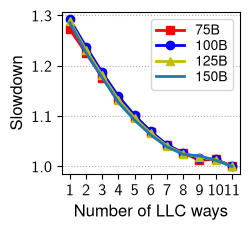

In [39]:
def plot_metrics(dfmetric,metric_name,benchmarks,fontsize=12):
    ax=dfmetric[benchmarks].plot(fontsize=fontsize,figsize=(2.6,2.4),style=['rs-','bo-','y^-'], linewidth=2.0)
    ax.yaxis.grid(which='major', linestyle=':')
    plt.ylabel(metric_name,fontsize=fontsize)
    plt.xlabel("Number of LLC ways",fontsize=fontsize) 
    plt.xticks(np.arange(1,12,1),fontsize=fontsize)
    plt.legend(labelspacing=0.2)
    return ax
    

ipbilion=[to_billion(w) for w in iwc]    
plot_metrics(build_slowdown_curves(dfs_astar),"Slowdown",ipbilion)
plt.tight_layout()
plt.savefig("slowdown-astar.pdf")

/var/folders/mh/bw844_b96k94v1jcypydkhk00000gn/T/ipykernel_86035/1891464606.py:15: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  slowdf.set_index("NR_WAYS",inplace=True)


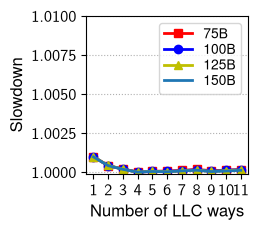

In [40]:
dfsb=[ get_bench_dfs(csv_df[w])["imagick17"] for w in iwc]
plot_metrics(build_slowdown_curves(dfsb),"Slowdown",ipbilion)
plt.ylim(top=1.01,bottom=0.9999)
plt.tight_layout()
plt.savefig("slowdown-imagick.pdf")

/var/folders/mh/bw844_b96k94v1jcypydkhk00000gn/T/ipykernel_86035/1891464606.py:15: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  slowdf.set_index("NR_WAYS",inplace=True)


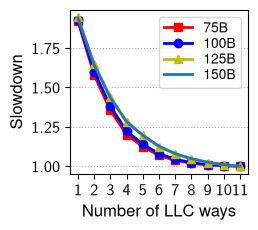

In [41]:
dfsb=[ get_bench_dfs(csv_df[w])["xalancbmk17"] for w in iwc]
plot_metrics(build_slowdown_curves(dfsb),"Slowdown",ipbilion)
plt.tight_layout()
plt.savefig("slowdown-xalancbmk17.pdf")

/var/folders/mh/bw844_b96k94v1jcypydkhk00000gn/T/ipykernel_86035/1891464606.py:15: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  slowdf.set_index("NR_WAYS",inplace=True)


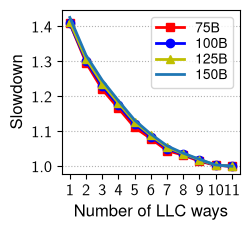

In [42]:
dfsb=[ get_bench_dfs(csv_df[w])["soplex06"] for w in iwc]
plot_metrics(build_slowdown_curves(dfsb),"Slowdown",ipbilion)
plt.tight_layout()
plt.savefig("slowdown-soplex.pdf")

# LLCMPKI over time

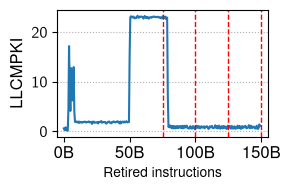

In [43]:
def plot_metric(profile_file, metric="llcmpki", ylabel="LLCMPKI", fontsize=12, figsize=(3, 2)):
    df = pd.read_csv(profile_file)
    ax = df[metric].plot(fontsize=fontsize, figsize=figsize)

    for x, label in zip([150, 200, 250, 300], ["75B", "100B", "125B", "150B"]):
        ax.axvline(x=x, color="red", linestyle="--", linewidth=1)
        ymax = ax.get_ylim()[1]
        #ax.text(x * 1.05, ymax * 0.98, label, color="red", fontsize=10,
        #        rotation=90, va="top", ha="center")

    ticks = ax.get_xticks()
    ax.set_xticks(ticks, labels=[f"{tick / 2:g}B" for tick in ticks])

    plt.xlim(left=-10,right=310)

    plt.ylabel(ylabel, fontsize=fontsize)
    plt.xlabel("Retired instructions")
    ax.yaxis.grid(which="major", linestyle=":")
    plt.tight_layout()
    return ax


plot_metric("astar06_4.profile.csv")
plt.savefig("astar-llcmpki.pdf")

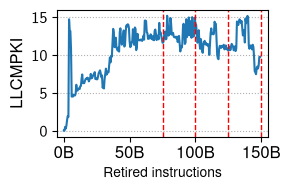

In [44]:
plot_metric("soplex06_4.profile.csv")
plt.savefig("soplex-llcmpki.pdf")

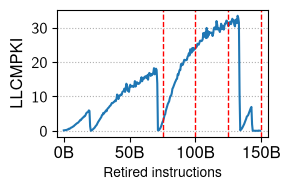

In [45]:
plot_metric("xalancbmk17_4.profile.csv")
plt.savefig("xalancbmk17-llcmpki.pdf")

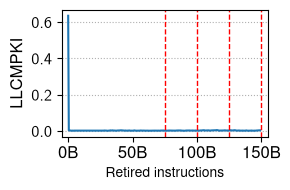

In [46]:
plot_metric("imagick17_4.profile.csv")
plt.savefig("imagick17-llcmpki.pdf")